In [12]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rc
from scipy.signal import convolve,deconvolve
from numpy.fft import fft
from scipy.signal import wiener as wiener1
from skimage.filters import wiener as wiener2
from skimage.restoration import wiener as wiener3
from skimage.restoration import unsupervised_wiener

rc({"text.usetex": True
    ,
    'family': 'serif', 'serif': ['Computer Modern'],
    })
plt.rcParams.update({'font.size': 18})

### test

Text(0.5, 1.0, 'valovna domena')

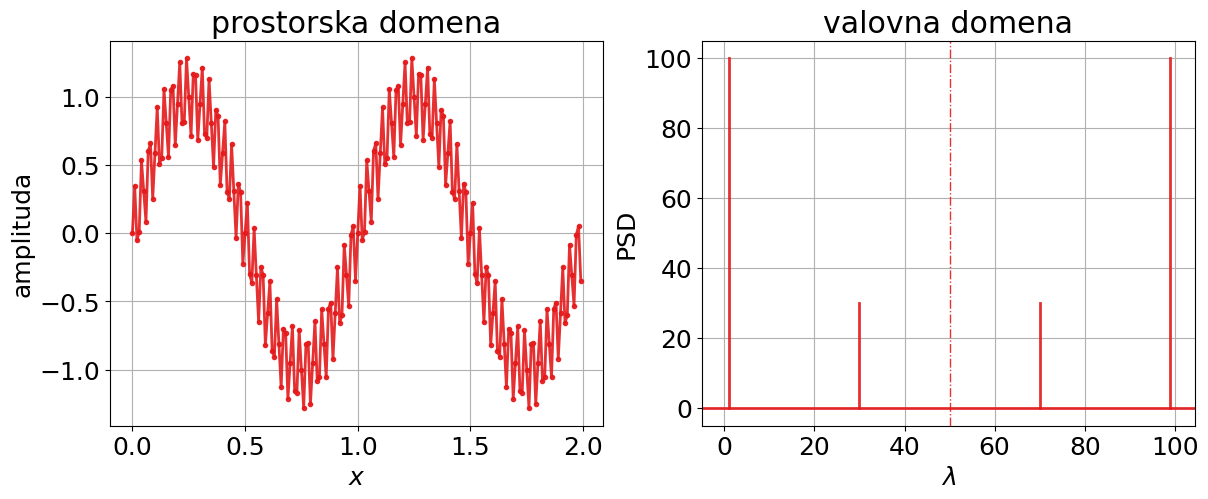

In [13]:
f0 = [100]
#f_vz=5 #frek vzorčenja
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
cmap=plt.get_cmap('Set1')
col=0
linesize=2*len(f0)
for f_vz in f0:
    t0=1/f_vz #perioda
    f_sig=1 #frekvenca signala
    t0_sig=1/f_sig #perioda *2*pi
    f_šum=np.array([30]) #frekvence šuma
    #f_šum=np.random.random(size=100)*100
    ampl=np.array([0.3])
    #amp=np.random.random(size=100)
    t0_šum=1/f_šum #perioda *2*pi
    t=np.arange(0,2*t0_sig+0,t0)
    x=np.sin(2 * np.pi*f_sig*t)
    for f,a in zip(f_šum,ampl):
        x+=a*np.sin(2 * np.pi*f*t)
    ax1.plot(t,x,'.-', color=cmap(col),alpha=0.9,linewidth=linesize)

    X=np.fft.fft(x)
    n=np.arange(len(X))
    T=len(X)/f_vz
    freq= n/T
    #ax2.plot(freq, np.abs(X), color=cmap(col),alpha=0.9)
    for i in range(len(freq)):
        ax2.plot([freq[i], freq[i]], [0, np.abs(X[i])], color=cmap(col), alpha=0.9,linewidth=linesize)
    ax2.axhline(0, color=cmap(col),alpha=0.9,linewidth=linesize)
    #line1=ax2.axvline(f_sig,color='g')
    line2=ax2.axvline(f_vz/2, color=cmap(col),label=f'$f_{{vz}}=${f_vz}',alpha=0.9,linestyle='dashdot',linewidth=1)
    col+=1
    linesize-=2
ax1.grid()
ax1.set_xlabel('$x$')
ax1.set_ylabel('amplituda')
ax1.set_title('prostorska domena')
#plt.legend()
#ax2.legend([line1], ['$f_{sig}$'],loc='best')
ax2.grid()
ax2.set_xlabel('$\lambda$')
ax2.set_ylabel('PSD')
ax2.set_title('valovna domena')
#plt.savefig('slike/testni.pdf',bbox_inches='tight')
#plt.savefig('fourier_puscanje')

## test dekonvolucija

array([2.02226709])

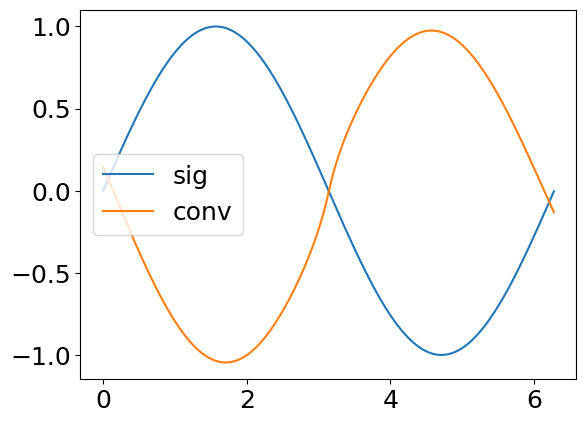

In [14]:
f_sig=1 #frekvenca signala
t0_sig=1/f_sig #perioda *2*pi
t=np.arange(0,t0_sig*2*np.pi,t0_sig/100)
signal=np.sin(t)
def f(x):
    tau=7
    return 1/2/tau * np.e**(-np.abs(t)*tau)
filt = f(t)
#filt=filt[filt>0.0]
for i in range(int(len(signal)/2)):
    filt[-i]=filt[i]
convolved=convolve(filt,signal,mode='same',method='auto')
deconv,_=deconvolve(convolved,filt)
# n=len(signal)-len(filt)+1
# s=(len(signal)-n)/2
# deconv_res = np.zeros(len(signal))
# deconv_res[s:len(signal)-s-1]
# deconv = deconv_res

plt.plot(t,signal,label='sig')
plt.plot(t,convolved,label='conv')
#plt.plot(t,filt,label='filt')
#plt.plot(t,deconv,label='deconv')
#plt.yscale('log')
plt.legend()
deconv

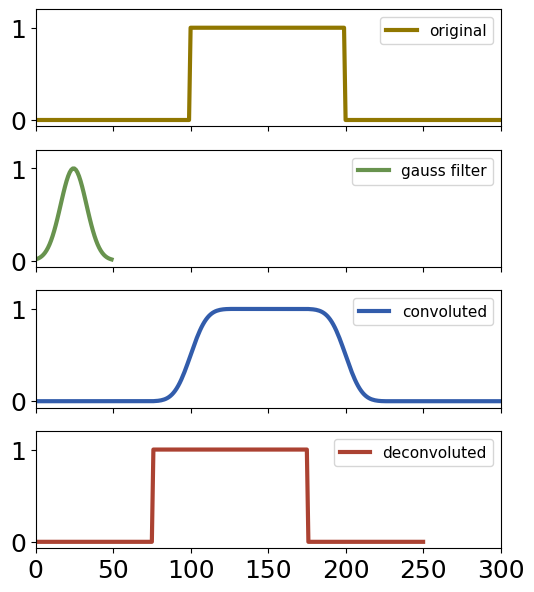

In [15]:
import numpy as np
import scipy.signal
import matplotlib.pyplot as plt

# let the signal be box-like
signal = np.repeat([0., 1., 0.], 100)
# and use a gaussian filter
# the filter should be shorter than the signal
# the filter should be such that it's much bigger then zero everywhere
gauss = np.exp(-( (np.linspace(0,50)-25.)/float(12))**2 )

# calculate the convolution (np.convolve and scipy.signal.convolve identical)
# the keywordargument mode="same" ensures that the convolution spans the same
#   shape as the input array.
#filtered = scipy.signal.convolve(signal, gauss, mode='same') 
filtered = np.convolve(signal, gauss, mode='same') 

deconv,  _ = scipy.signal.deconvolve( filtered, gauss )
#the deconvolution has n = len(signal) - len(gauss) + 1 points
n = len(signal)-len(gauss)+1
# so we need to expand it by 
s = (len(signal)-n)/2
#on both sides.
deconv_res = np.zeros(len(signal))
#deconv_res[s:len(signal)-s-1] = deconv
deconv_res[int(s):int(s + len(deconv))] = deconv
#deconv = deconv_res
# now deconv contains the deconvolution 
# expanded to the original shape (filled with zeros) 


#### Plot #### 
fig , ax = plt.subplots(nrows=4, figsize=(6,7))

ax[0].plot(signal,            color="#907700", label="original",     lw=3 ) 
ax[1].plot(gauss,          color="#68934e", label="gauss filter", lw=3 )
# we need to divide by the sum of the filter window to get the convolution normalized to 1
ax[2].plot(filtered/np.sum(gauss), color="#325cab", label="convoluted" ,  lw=3 )
ax[3].plot(deconv,         color="#ab4232", label="deconvoluted", lw=3 ) 

for i in range(len(ax)):
    ax[i].set_xlim([0, len(signal)])
    ax[i].set_ylim([-0.07, 1.2])
    ax[i].legend(loc=1, fontsize=11)
    if i != len(ax)-1 :
        ax[i].set_xticklabels([])

#plt.savefig(__file__ + ".png")
plt.show()   

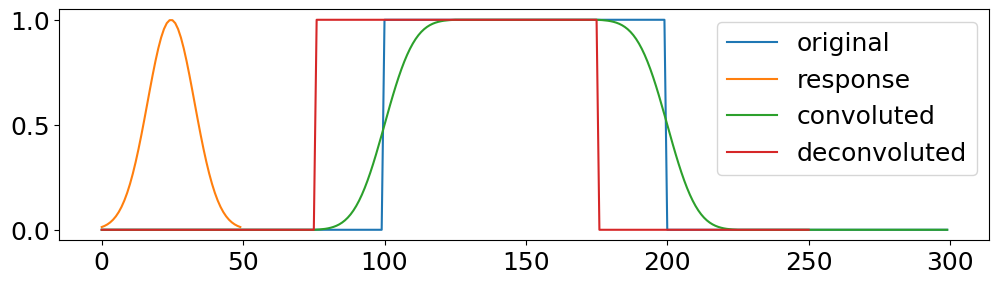

In [16]:
# let the signal be box-like
signal = np.repeat([0., 1., 0.], 100)
t=np.linspace(0,len(signal),len(signal))
#signal=np.sin(t)
# and use a gaussian filter
# the filter should be shorter than the signal
# the filter should be such that it's much bigger then zero everywhere
gauss = np.exp(-( (np.linspace(0,50)-25.)/float(12))**2 )
#gauss=f(np.arange(len(signal)))
#print(gauss.min() ) # = 0.013 >> 0

# calculate the convolution (np.convolve and scipy.signal.convolve identical)
# the keywordargument mode="same" ensures that the convolution spans the same
#   shape as the input array.
#filtered = scipy.signal.convolve(signal, gauss, mode='same') 
filtered = np.convolve(signal, gauss, mode='same') 

deconv,  _ = deconvolve( filtered, gauss )
#the deconvolution has n = len(signal) - len(gauss) + 1 points
#n = len(signal)-len(gauss)+1
# so we need to expand it by 
#s = (len(signal)-n)//2
#on both sides.
#deconv_res = np.zeros(len(signal))
#deconv_res[int(s):int(len(signal)+n)] = deconv
#deconv_res[int(s):int(s + len(deconv))] = deconv
#deconv = deconv_res
# now deconv contains the deconvolution 
# expanded to the original shape (filled with zeros) 


#### Plot #### 
fig , ax = plt.subplots(nrows=1, figsize=(12,3))

ax.plot(signal, label="original") 
ax.plot(gauss, label="response" )
# we need to divide by the sum of the filter window to get the convolution normalized to 1
ax.plot(filtered/np.sum(gauss), label="convoluted" )
ax.plot(deconv, label="deconvoluted" ) 

# for i in range(len(ax)):
#     #ax[i].set_xlim([0, len(signal)])
#     #ax[i].set_ylim([-0.07, 1.2])
#     ax[i].legend(loc=1, fontsize=11)
#     if i != len(ax)-1 :
#         ax[i].set_xticklabels([])
plt.legend()
#plt.savefig("slike/primer_dekonv.pdf")
plt.show()

# dekonvolucija

In [17]:
sig0=np.loadtxt('podatki/signal0.dat')
sig1=np.loadtxt('podatki/signal1.dat')
sig2=np.loadtxt('podatki/signal2.dat')
sig3=np.loadtxt('podatki/signal3.dat')
def prenosna(t):
    tau=16
    return 1/(2*tau) * np.exp(-np.abs(t)/tau)

/home/aljaz/anaconda3/lib/python3.11/site-packages/matplotlib/cbook.py:1699: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/aljaz/anaconda3/lib/python3.11/site-packages/matplotlib/cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


Text(0, 0.5, 'signal($t$)')

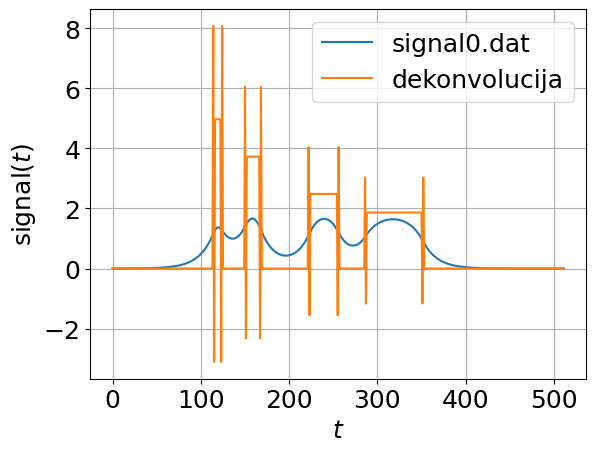

In [18]:
sig=sig0
x=np.arange(0,len(sig))
r=prenosna(x)
for i in range(int(len(sig)/2)):
    r[-i]=r[i]
fr=fft(r)
f0=fft(sig)
f0abs=np.abs(f0)**2
invert=np.fft.ifft(f0/fr)

povprecje=0
f0relat=[f0[i]/(f0[i]+povprecje) for i in range(len(f0))]
invert_2=np.fft.ifft(f0/fr*f0relat)

deconv,_ = deconvolve(sig, r)
plt.plot(x,sig, label='signal0.dat')
#plt.plot(x,deconv,'--',label='scipy')
plt.plot(x,invert,label='dekonvolucija')
#plt.plot(x,invert_2)
plt.grid()
plt.legend()
plt.xlabel('$t$')
plt.ylabel('signal($t$)')

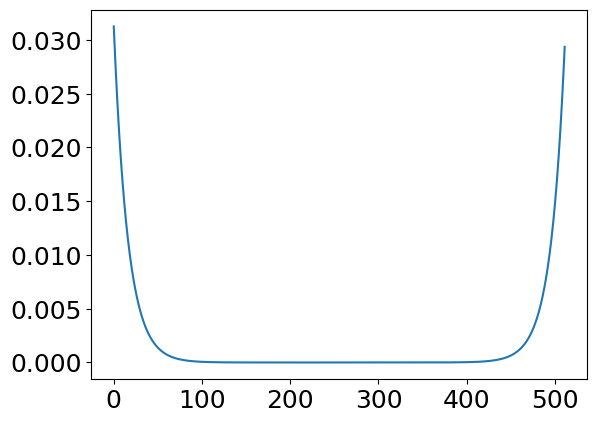

In [19]:
plt.plot(x,r)

Text(0, 0.5, 'signal($t$)')

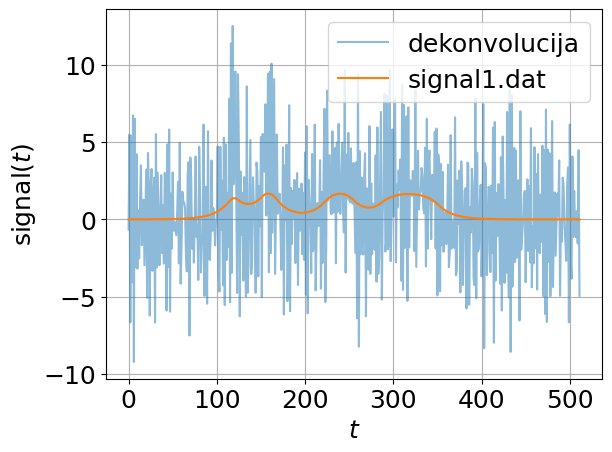

In [20]:
sig=sig1 #c(t)
x=np.arange(0,len(sig))
r=prenosna(x)#r(t)
for i in range(int(len(sig)/2)):
    r[-i]=r[i]
fr=fft(r)#R(f)
f0=fft(sig) #C(f)
f0abs=np.abs(f0)**2 #PSD C(f)
invert=np.fft.ifft(f0/fr) #time domain u(t)

_, u0 = deconvolve(sig, r) #ni ok
plt.plot(x,invert,label='dekonvolucija',alpha=0.5)
plt.plot(x,sig, label='signal1.dat')
#plt.plot(x,u0,label='scipy')
plt.grid()
plt.legend()
plt.xlabel('$t$')
plt.ylabel('signal($t$)')

Text(0, 0.5, 'amplituda')

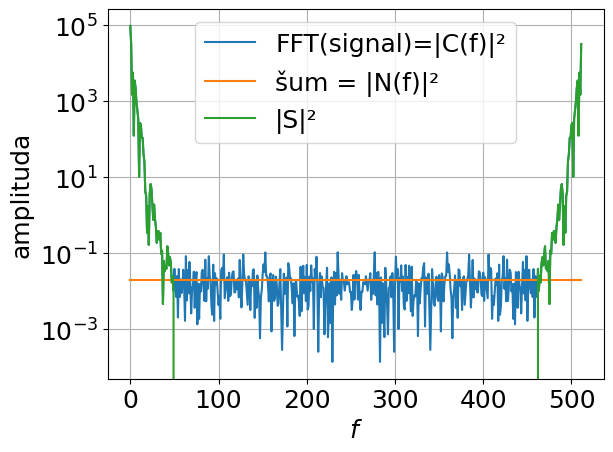

In [21]:
meja = 50
vsota = np.sum(f0abs[meja:-meja])
povprecje = vsota/(len(f0abs)-2*meja)
šum=np.full(len(x), povprecje) #N(f)
#šum=šum*f0abs
#N = np.abs(fft(šum))**2 #PSD
N=np.zeros(len(f0abs))
N[meja:-meja] = f0abs[meja:-meja]

f0relat=f0abs/(f0abs+šum) #phi(f) = S/(S+N), C=S+N!
f0relat=(f0abs-šum)/f0abs #phi(f) = (C-N)/C
##invert_2=np.fft.ifft(f0/fr*f0relat)
#S= np.abs(fft(sig-šum))**2
S=f0abs-N
U = f0*f0relat/fr #U(f) aproks.
filtered = np.fft.ifft(U)#u(t)

filter_f0=wiener1(f0abs,noise=šum) #scipy
filtered_1 = np.fft.ifft(f0*filter_f0/fr)

#freq domain
#i=50
#plt.plot(x[i],f0abs[i],'o')
plt.plot(x,f0abs,label='FFT(signal)=|C(f)|²')
plt.plot(x,šum, label='šum = |N(f)|²')
#plt.plot(x,f0relat,label='Wiener filter',alpha=0.6)
plt.plot(x,S,label='|S|²')
#plt.plot(x,filter_f0,label='scipy')
plt.yscale('log')
plt.legend()
plt.grid()
plt.xlabel('$f$')
plt.ylabel('amplituda')

Text(0, 0.5, 'signal($t$)')

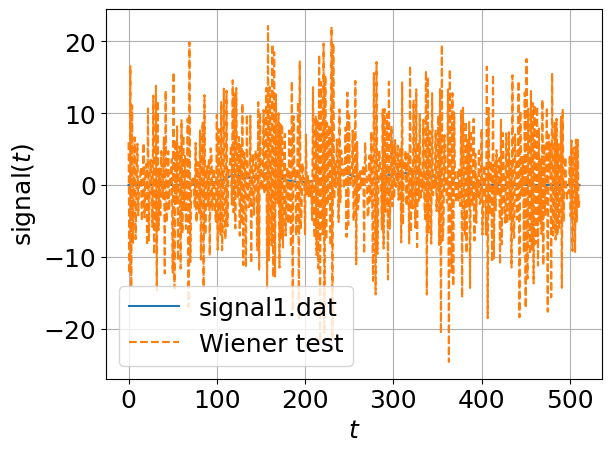

In [22]:
#time domain
#plt.plot(x,invert,label='dekonvolucija',alpha=0.5)
plt.plot(x,sig, label='signal1.dat')
plt.plot(x,filtered,'--',label='Wiener test')
#plt.plot(x,filtered_1,label='scipy')
plt.grid()
plt.legend()
plt.xlabel('$t$')
plt.ylabel('signal($t$)')

/home/aljaz/anaconda3/lib/python3.11/site-packages/matplotlib/cbook.py:1699: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/aljaz/anaconda3/lib/python3.11/site-packages/matplotlib/cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)
/home/aljaz/anaconda3/lib/python3.11/site-packages/matplotlib/transforms.py:2855: ComplexWarning: Casting complex values to real discards the imaginary part
  vmin, vmax = map(float, [vmin, vmax])
/home/aljaz/anaconda3/lib/python3.11/site-packages/matplotlib/cbook.py:1699: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/aljaz/anaconda3/lib/python3.11/site-packages/matplotlib/cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)
/home/aljaz/anaconda3/lib/python3.11/site-packages/matplotlib/transforms.py:285

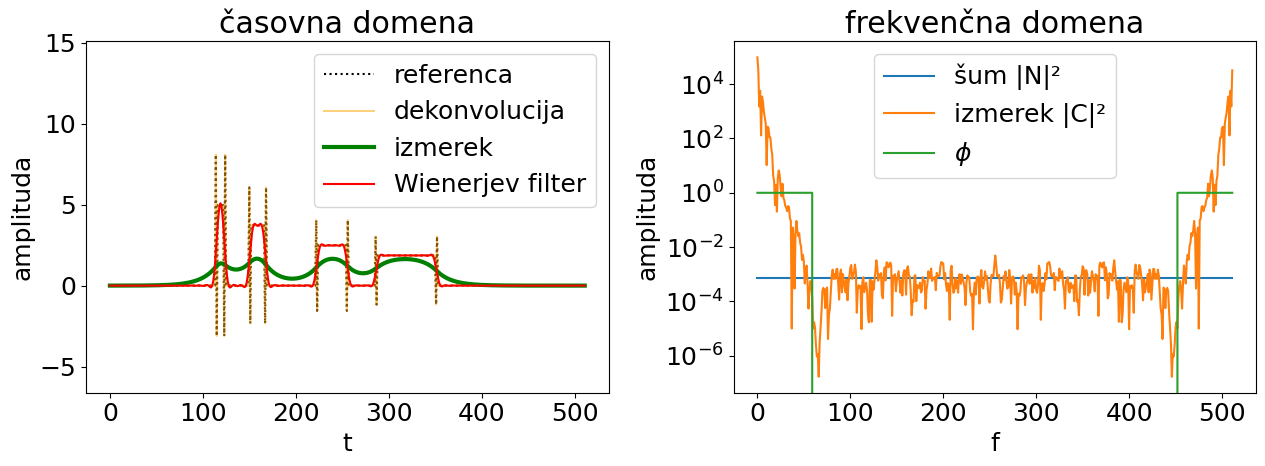

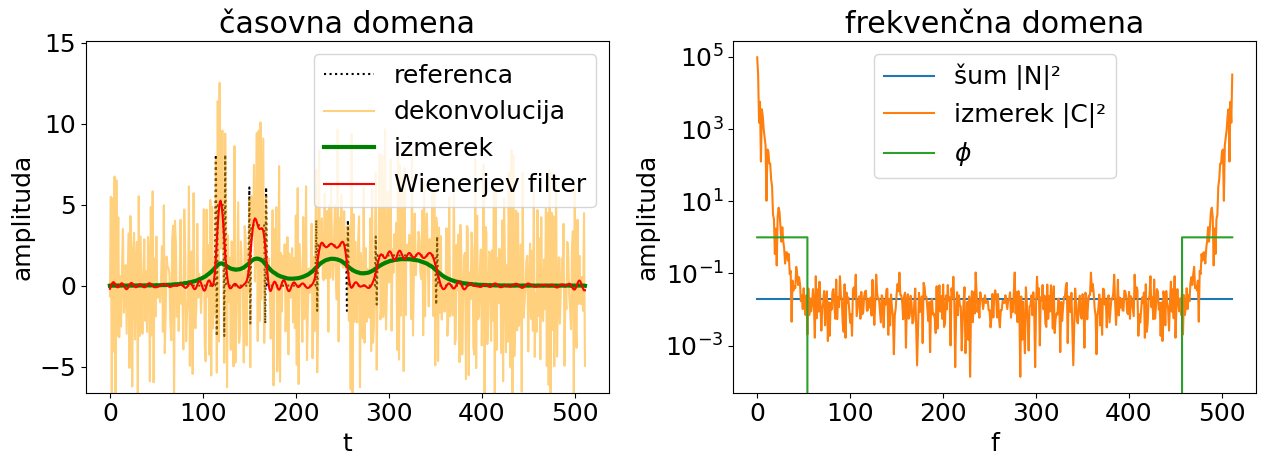

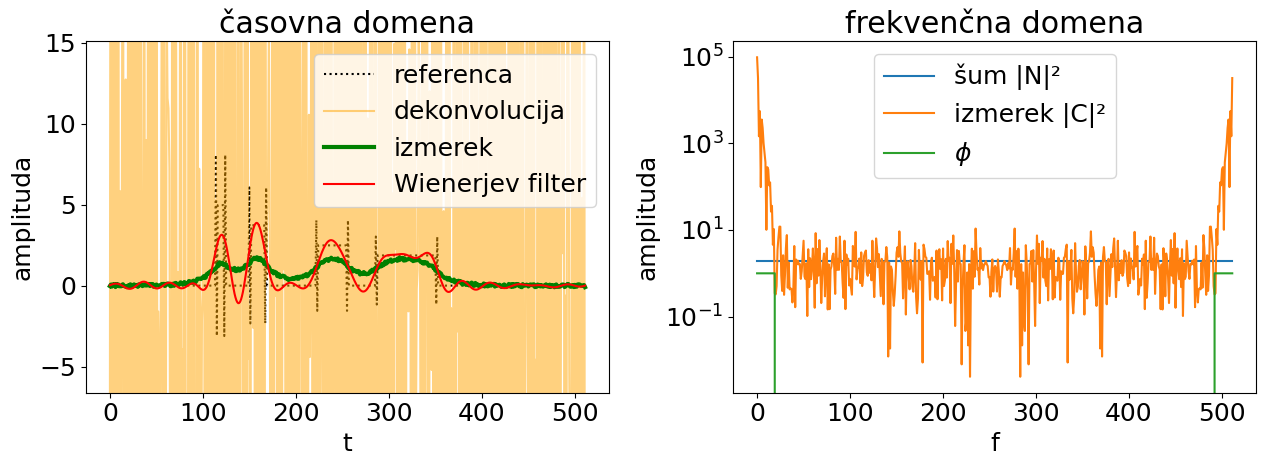

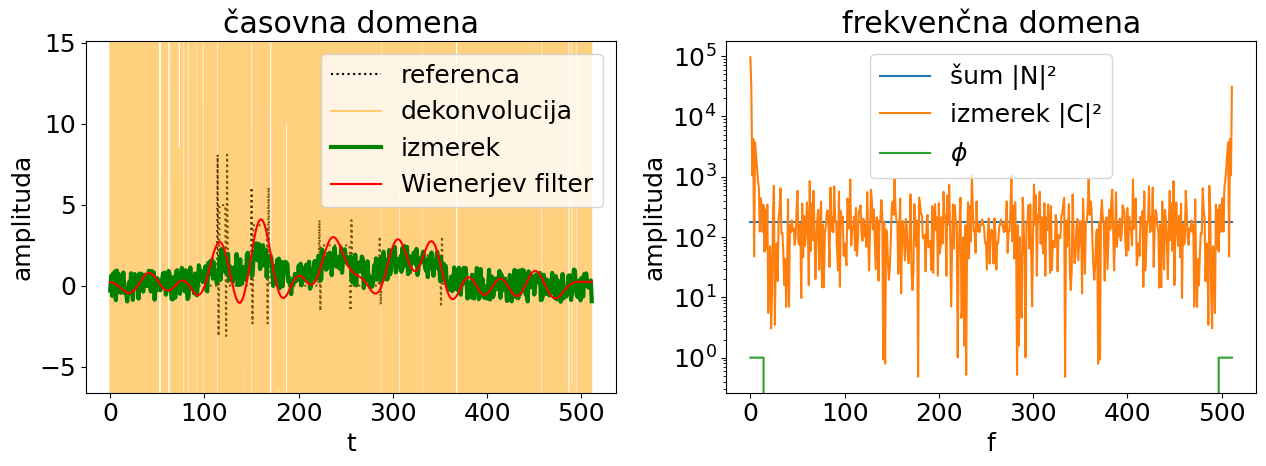

In [25]:
def wiener_f(datoteka, meja):
    #signal_data = sig0
    signal_data=np.loadtxt('podatki/'+datoteka)
    response_function = lambda t, tau: 1/(2*tau)*np.exp(-np.abs(t)/tau)
    tau = 16
    t = np.arange(0, len(signal_data))
    rt = response_function(t, tau)
    for i in range(int(len(signal_data)/2)):
        rt[-i]=rt[i]
    signal_fft = np.fft.fft(signal_data)
    signal_freq = np.fft.fftfreq(len(signal_data))
    response_fft = np.fft.fft(rt)

    deconvolved_fft = signal_fft / response_fft
    deconvolved = np.fft.ifft(deconvolved_fft) #brez filtra

    ref = np.loadtxt('podatki/signal0.dat')
    ref_deconv = np.fft.ifft(np.fft.fft(ref)/response_fft)

    signal_PSD = np.abs(signal_fft)**2
    response_PSD = np.abs(response_fft)**2

    #meja = 25 #kalibriraj!!
    vsota = np.sum(signal_PSD[meja:-meja])
    povprecje = vsota/(len(signal_PSD)-2*meja)
    šum=np.full(len(signal_data), povprecje) #N(f) PSD šuma

    wiener_filter = np.zeros_like(signal_PSD)
    wiener_filter[0:meja] = 1
    wiener_filter[-meja:] = 1
    #wiener_filter=wiener_filter*signal_PSD[0]-šum

    # coef = np.polyfit(signal_freq[:meja],signal_PSD[:meja],deg=1)
    # poli=np.poly1d(coef)
    # wiener_filter[meja:2*meja] = poli(signal_freq[:meja])/max(poli(signal_freq[:meja]))
    # coef = np.polyfit(signal_freq[-meja:-1],signal_PSD[-meja:-1],deg=1)
    # poli=np.poly1d(coef)
    # wiener_filter[-2*meja+1:-meja] = poli(signal_freq[-meja:-1])/max(poli(signal_freq[-meja:-1]))
    
    #wiener_filter = wiener_filter-šum/max(signal_PSD)
    #wiener_filter = (signal_PSD - noise_PSD) / signal_PSD #ne direkt!
    deconvolved_fft = signal_fft * wiener_filter / response_fft
    deconvolved_wiener = np.fft.ifft(deconvolved_fft)

    # S=abs(signal_PSD-noise_PSD)**2
    # phi=abs((signal_PSD-noise_PSD)/signal_PSD)

    plt.figure(figsize=(13,5))
    gs = plt.GridSpec(1, 2, width_ratios=[1, 1])
    plt.subplot(gs[0])
    plt.plot(t, ref_deconv, 'k:', label='referenca')
    plt.plot(t, deconvolved, color='orange',label='dekonvolucija',alpha=0.5)
    plt.plot(t, signal_data,'g' ,label='izmerek',linewidth=3)
    plt.plot(t, deconvolved_wiener, 'r-', label='Wienerjev filter')
    plt.xlabel('t')
    plt.ylabel('amplituda')
    plt.legend()
    plt.title('časovna domena')
    plt.ylim((min(ref_deconv)-3.5, max(ref_deconv)+7))
    #plt.savefig('slike/casovno_sig0.pdf')
    #plt.tight_layout()
    #plt.show()

    plt.subplot(gs[1])
    plt.plot(šum,label='šum |N|²')
    plt.plot(signal_PSD,label='izmerek |C|²')
    plt.plot(wiener_filter,label='$\phi$')
    #plt.plot(poli(np.arange(meja)))
    #plt.plot(meja, signal_PSD[meja],'ro')
    #plt.plot(response_PSD)
    plt.yscale('log')
    plt.xlabel('f')
    plt.ylabel('amplituda')
    plt.legend()
    plt.title('frekvenčna domena')
    plt.tight_layout()
    #plt.savefig('slike/'+datoteka+'.pdf')
    #plt.show()

    # plt.plot(t, rt)
    # plt.xlabel('f')
    # plt.ylabel('amplituda')
    # plt.title('prenosna funkcija')
    # plt.tight_layout()
    # plt.show()

wiener_f('signal0.dat', 60)
# plt.savefig('slike/signal0.pdf')
wiener_f('signal1.dat', 55)
# plt.savefig('slike/signal1.pdf')
wiener_f('signal2.dat', 20)
# plt.savefig('slike/signal2.pdf')
wiener_f('signal3.dat', 15)
# plt.savefig('slike/signal3.pdf')

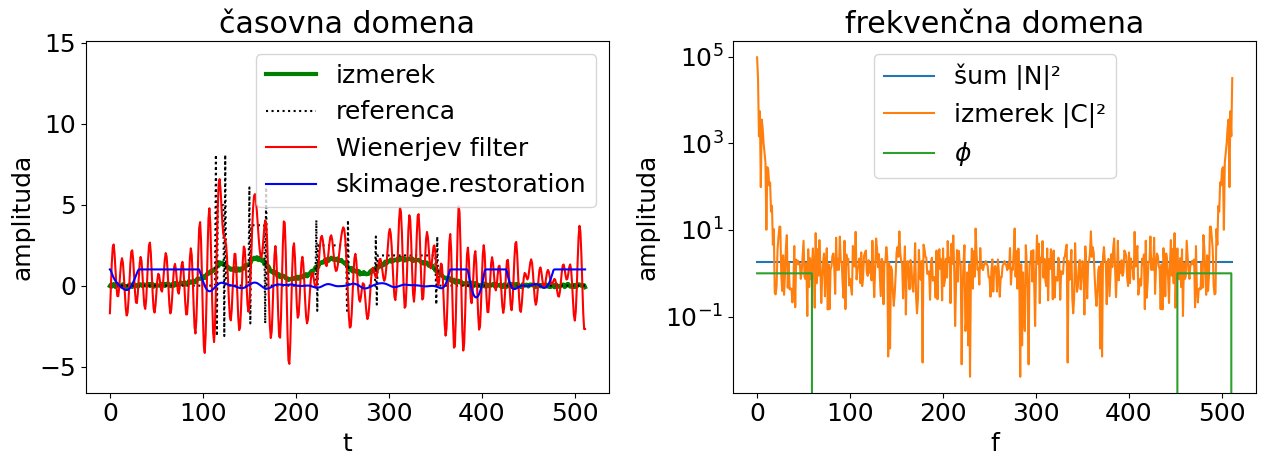

In [24]:
def wiener_knj(datoteka, meja):
    #signal_data = sig0
    signal_data=np.loadtxt('podatki/'+datoteka)
    response_function = lambda t, tau: 1/(2*tau)*np.exp(-np.abs(t)/tau)
    tau = 16
    t = np.arange(0, len(signal_data))
    rt = response_function(t, tau)
    for i in range(int(len(signal_data)/2)):
        rt[-i]=rt[i]
    signal_fft = np.fft.fft(signal_data)
    response_fft = np.fft.fft(rt)
    signal_PSD = np.abs(signal_fft)**2

    ref = np.loadtxt('podatki/signal0.dat')
    ref_deconv = np.fft.ifft(np.fft.fft(ref)/response_fft)

    # lastni
    vsota = np.sum(signal_PSD[meja:-meja])
    povprecje = vsota/(len(signal_PSD)-2*meja)
    šum=np.full(len(signal_data), povprecje) #N(f) PSD šuma

    wiener_filter = np.zeros_like(signal_PSD)
    wiener_filter[0:meja] = 1
    wiener_filter[-meja:-1] = 1

    deconvolved_fft = signal_fft * wiener_filter / response_fft
    deconvolved_wiener = np.fft.ifft(deconvolved_fft)

    # scipy
    # deconvolved_fft = wiener1(signal_data)/response_fft
    # deconvolved_w1 = np.fft.ifft2(deconvolved_fft)

    #skimage.filters
    # deconvolved_fft = wiener2(np.array([signal_data]), impulse_response=response_function)
    # deconvolved_w2 = np.fft.ifft2(deconvolved_fft)

    #skimage.restoration
    deconvolved_w3 = wiener3(signal_data, psf=rt, balance=1)

    # unsupervised!
    # deconvolved_w4,_ = unsupervised_wiener(np.array([signal_data]), np.array([rt]))

    plt.figure(figsize=(13,5))
    gs = plt.GridSpec(1, 2, width_ratios=[1, 1])
    plt.subplot(gs[0])
    plt.plot(t, signal_data,'g' ,label='izmerek',linewidth=3)
    plt.plot(t, ref_deconv, 'k:', label='referenca')
    plt.plot(t, deconvolved_wiener, 'r-', label='Wienerjev filter')
    plt.plot(t, deconvolved_w3, 'b-', label='skimage.restoration')
    plt.xlabel('t')
    plt.ylabel('amplituda')
    plt.legend()
    plt.title('časovna domena')
    plt.ylim((min(ref_deconv)-3.5, max(ref_deconv)+7))

    plt.subplot(gs[1])
    plt.plot(šum,label='šum |N|²')
    plt.plot(signal_PSD,label='izmerek |C|²')
    plt.plot(wiener_filter,label='$\phi$')
    plt.yscale('log')
    plt.xlabel('f')
    plt.ylabel('amplituda')
    plt.legend()
    plt.title('frekvenčna domena')
    plt.tight_layout()
    #plt.savefig('slike/'+datoteka+'.pdf')
    plt.show()

wiener_knj('signal2.dat', 60)